torch.Size([16, 3, 256, 256])


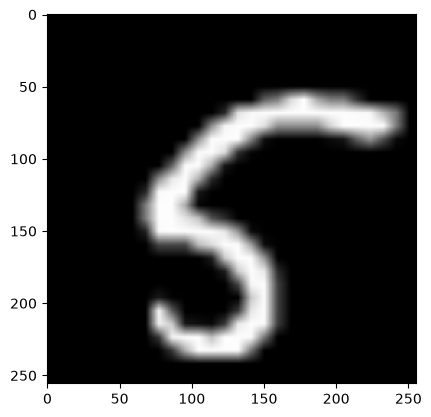

In [5]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch


def get_dataloader(batch_size):
    transform = transforms.Compose([
        transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor(),                           # Shape: (1, 256, 256)
        transforms.Lambda(lambda x: x.repeat(3, 1, 1))   # Shape: (3, 256, 256)
    ])

    dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    return dataloader

dataloader = get_dataloader(batch_size=16) 
img, _ = next(iter(dataloader))
print(img.shape)  # Output: torch.Size([3, 256, 256])

plt.imshow(img[0].permute(1,2,0))


In [6]:
from unet import UNet

model = UNet(in_channels=3, out_channels=3)
output = model(img) 
print("Input shape :", img.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 3, 256, 256])


# Diffusion train

torch.Size([100])


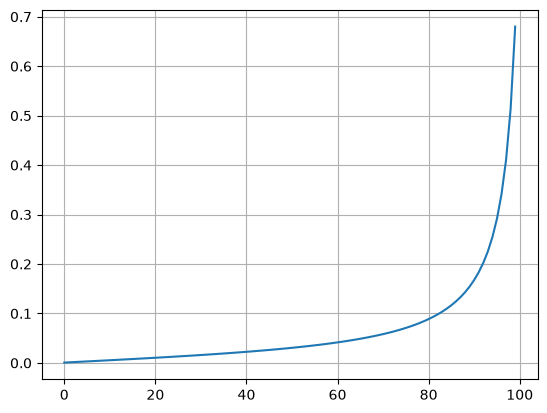

In [7]:

def diffusion_schedule(T, max_signal_rate=0.9999, min_signal_rate=0.02):
    # Generate T + 1 diffusion times
    t = torch.linspace(0, 1, T + 1)
    # Convert signal limits to angles
    start_angle = torch.arccos(torch.tensor(max_signal_rate))
    end_angle = torch.arccos(torch.tensor(min_signal_rate))
    # Calculate signal rates
    angles = start_angle + t * (end_angle - start_angle)
    signal_rates = torch.cos(angles)
    # Calculate cumulative signal coefficients
    alpha_bars = signal_rates ** 2

    # Normalize initial cumulative signal to 1
    alpha_bars = alpha_bars / alpha_bars[0]

    # Calculate T beta values
    betas = 1 - alpha_bars[1:] / alpha_bars[:-1]

    return torch.clamp(betas, min=0.0, max=0.999)

T = 100
betas = diffusion_schedule(T)

print(betas.shape)  # torch.Size([1000])

plt.plot(betas)
plt.grid()

In [ ]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

batch_size = 16
dataloader = get_dataloader(batch_size=batch_size) 

T = 100
epochs = 1
model = UNet(in_channels=3, out_channels=3)
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,  # Learning rate
    weight_decay=1e-4,  # L2 penalty (optional)
)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"DEVICE={device}")
model = model.to(device)

# Generate the beta schedule
betas = diffusion_schedule(T).to(device)

# Precompute cumulative signal coefficients
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

batch_losses = []
for epoch in range(epochs):
    model.train()
    for i, (img_batch, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch + 1}/{epochs}")):
        optimizer.zero_grad()
         # img_batch: 16, 3, 256, 256
        img_batch = img_batch.to(device)
        batch_loss = 0.0
        for img in img_batch: 
            # img: 3, 256, 256
            t = torch.randint(0, T, (1,), device=device).item()
            epsilon = torch.randn_like(img) # 3, 256, 256
            alpha_bar_t = alpha_bars[t]

            noisy_image = torch.sqrt(alpha_bar_t) * img + torch.sqrt(1.0 - alpha_bar_t) * epsilon # 3, 256, 256
            noisy_images = noisy_image.unsqueeze(0) # 1, 3, 256, 256
            pred_noise = model(noisy_images).squeeze() # 3, 256, 256

            #loss = torch.norm((pred_noise - epsilon))**2
            #mean_loss = loss / batch_size
            loss = F.mse_loss(pred_noise, epsilon)
            mean_loss.backward()
            batch_loss += loss.item()
        optimizer.step()
        batch_loss /= len(img_batch)
        if i % 10 == 0:
            print(f"i={i}, loss={batch_loss}")
        batch_losses.append(batch_loss)
    


DEVICE=cuda


Epoch 1/1:   0%|          | 0/3750 [00:00<?, ?it/s]


RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.

In [ ]:
t

86